# Neuro-Screen | Reproducible cognitive-symptom classification
Attach the survey CSV in Kaggle and select **Run All**. The primary outcome is elevated cognitive symptoms among respondents meeting the observed sleep-risk rule. The secondary task is sleep-risk classification in the full survey. The analysis estimates internal cross-validation performance. All intervals, counts and tests refer to the stated task and outer fold.

CPU notebook. Attach Dataset.csv and select Run All. The new cognitive experiments are exploratory. Each uses the same five outer test folds as the original comparison. The extra inner model fits for threshold selection increase training time.

In [35]:
# Optional setup in a fresh notebook environment (uncomment to install):
# %pip install catboost xgboost lightgbm torch scikit-learn pandas numpy matplotlib scipy
from pathlib import Path
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from scipy.stats import binomtest
from sklearn.metrics import roc_curve, mean_absolute_error
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, confusion_matrix)
from sklearn.model_selection import StratifiedKFold, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from IPython.display import display

SEED = 42
torch.set_num_threads(2)
CSV_PATH = None  # Optionally set the full path to your survey CSV.
root = Path('/kaggle/input') if Path('/kaggle/input').is_dir() else Path.cwd()
out = (Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path.cwd()) / 'neuro_screen_experiment_results'
out.mkdir(exist_ok=True)
if CSV_PATH is None:
    names = {'dataset.csv', 'detection of cognitive impairment in insomniac university students dataset.csv'}
    matches = [p for p in root.rglob('*') if p.is_file() and p.name.casefold() in names]
    if len(matches) != 1:
        raise ValueError(f'Attach Dataset.csv or set CSV_PATH to its exact path. Matches: {matches}')
    CSV_PATH = matches[0]

## 1. Load the survey and document provenance and ethics

In [36]:
df = pd.read_csv(CSV_PATH)
df.columns = df.columns.str.strip()
for c in df.select_dtypes('object'):
    df[c] = df[c].str.strip().str.replace('â€“','-',regex=False)

import hashlib
# Replace these entries only with verified details from the data custodian.
study_details = {
    'dataset_source': 'Study-supplied cross-sectional university student survey CSV; Bangladesh setting reported in the manuscript.',
    'public_repository_or_doi': 'Unverified',
    'recruitment_and_collection_dates': 'Unverified',
    'ethics_committee_and_approval_or_exemption': 'Unverified',
    'participant_consent_procedure': 'Unverified',
    'analysis_scope': 'Internal evaluation of self-reported questionnaire outcomes.'
}
source_record = {**study_details, 'filename': Path(CSV_PATH).name,
                 'sha256': hashlib.sha256(Path(CSV_PATH).read_bytes()).hexdigest(),
                 'rows_read': len(df)}
pd.Series(source_record, name='value').to_csv(out/'source_and_ethics.csv')
display(pd.Series(source_record))

dataset_source                                Study-supplied cross-sectional university stud...
public_repository_or_doi                                                             Unverified
recruitment_and_collection_dates                                                     Unverified
ethics_committee_and_approval_or_exemption                                           Unverified
participant_consent_procedure                                                        Unverified
analysis_scope                                Internal evaluation of self-reported questionn...
filename                                                                            Dataset.csv
sha256                                        d05bc31307e9fab685d7e346d009228310483a2db2216e...
rows_read                                                                                  2236
dtype: object

## 2. Calculate the cognitive score and define sleep-risk eligibility
Higher symptom burden gives a higher score (0–17). The score is converted to a binary target separately within each training split in Step 5. The outer training cutoff also defines the corresponding test labels.

In [37]:
maps = {
    'How would you rate your "Mental Stamina" (the ability to think hard for long periods)?': {'1 (Total Exhaustion)': 3, '2 (Fading Fast)': 2, '3 (Full Energy)': 0},
    'How often do you find yourself "spacing out" or losing your train of thought during conversations?': {'Never':0, 'Rarely':1, 'Sometimes':2, 'Always':3},
    'Do you experience "Audio Lag" (hearing someone speak but taking a few seconds to understand the meaning)?': {'No':0, 'Maybe':1, 'Yes':2},
    'How often do you forget basic information in your daily life?': {'Never':0, 'Rarely':1, 'Sometimes':2, 'Always':3},
    'How much do you rely on "external reminders" (alarms, notes, friends) to remember basic daily tasks?': {'Not at all':0, 'Sometimes':1, 'Completely dependent':2},
    'How frequently do you experience "Brain Fog" (confusion or lack of clarity)?': {'Never':0, 'Sometimes':1, 'Always':2},
    'Do you struggle with making quick decisions or solving logical problems?': {'Never':0, 'Sometimes':1, 'Always':2}
}
items = pd.DataFrame({c: df[c].map(mapping) for c,mapping in maps.items()})
if items.isna().any().any():
    raise ValueError('Missing or unknown symptom response. Inspect before analysis.')
score = items.sum(axis=1)
duration = 'On average, how many hours of actual sleep do you get per night?'
quality = 'How would you rate your overall sleep quality?'
age = 'What is your age?'
df[duration] = df[duration].str.replace('–', '-', regex=False)
durations = {'Less than 5 hours','5-6 hours','6-7 hours','7-8 hours','More than 8 hours'}
qualities = {'1 (Very Poor)','2 (Poor)','3 (Average)','4 (Good)','5 (Excellent)'}
if not df[duration].isin(durations).all() or not df[quality].isin(qualities).all():
    raise ValueError('Inspect missing or unknown sleep responses before computing the sleep flag.')
sleep = (df[duration].isin(['Less than 5 hours','5-6 hours']) |
         df[quality].isin(['1 (Very Poor)','2 (Poor)','3 (Average)'])).astype(int)

score.name = 'cognitive_score'
assert score.between(0, 17).all()
rubric = pd.DataFrame([{'question': q, 'answer': a, 'points': v}
                       for q, choices in maps.items() for a, v in choices.items()])
rubric.to_csv(out/'cognitive_scoring_key.csv', index=False)
display(rubric)
display(score.value_counts().sort_index().rename('respondents'))

,question,answer,points
0,"How would you rate your ""Mental Stamina"" (the ...",1 (Total Exhaustion),3
1,"How would you rate your ""Mental Stamina"" (the ...",2 (Fading Fast),2
2,"How would you rate your ""Mental Stamina"" (the ...",3 (Full Energy),0
3,"How often do you find yourself ""spacing out"" o...",Never,0
4,"How often do you find yourself ""spacing out"" o...",Rarely,1
5,"How often do you find yourself ""spacing out"" o...",Sometimes,2
6,"How often do you find yourself ""spacing out"" o...",Always,3
7,"Do you experience ""Audio Lag"" (hearing someone...",No,0
8,"Do you experience ""Audio Lag"" (hearing someone...",Maybe,1
9,"Do you experience ""Audio Lag"" (hearing someone...",Yes,2


cognitive_score
0       2
1       2
2       9
3      36
4      90
5     108
6     218
7     269
8     315
9     356
10    308
11    216
12    163
13     89
14     39
15     12
16      4
Name: respondents, dtype: int64

## 3. Build and audit the predictor set
The original feature filter retained the raw answers for all seven cognitive items. Here their raw and derived values are excluded. Cognitive load and fatigue may still be conceptually related to the target. All twelve predictors are self-reported, so common-method bias remains possible.

In [38]:
features = [
    'What is your age?',
    'What is your gender?',
    'What is your University name?',
    'Your current year of study?',
    'How many cups of caffeine (tea/coffee/energy drinks) do you have daily?',
    'How often do you use electronic devices (phone/laptop) in bed before sleep?',
    'How often do you feel cognitive load?',
    'How often do you feel stressed?',
    'How often do you wake up in the middle of the night?',
    'How many academic deadlines have you missed or delayed in the last month?',
    'To what extent do you feel sleep deprivation is lowering your GPA?',
    'How often does physical or mental fatigue prevent you from completing your daily goals?',
]
label_inputs = set(maps) | {duration, quality}
if label_inputs.intersection(features):
    raise ValueError('Label-defining survey questions must be excluded from predictors.')
X = df[features].copy()
X[age] = pd.to_numeric(X[age],errors='coerce').replace(2,np.nan)
cats = [c for c in features if c != age]
X[cats] = X[cats].fillna('Missing')
groups = {'Sleep risk': np.arange(len(df)), 'Cognitive symptoms': np.flatnonzero(sleep)}
for task, ids in groups.items():
    print(task, len(ids), 'eligible responses')
derived = {'cognitive_score','cognitive_impairment','insomniac'} | {q+'_score' for q in maps}
assert set(X.columns).isdisjoint(label_inputs | derived)
audit = pd.DataFrame({'field': list(dict.fromkeys([*df.columns, *sorted(derived)]))})
def field_role(field):
    if field in maps: return 'Cognitive target item'
    if field in (duration, quality): return 'Sleep-rule item'
    if field in derived: return 'Derived outcome or item score'
    if field in features: return 'Predictor'
    return 'Unused survey field'
audit['role'] = audit.field.map(field_role)
audit['used_as_predictor'] = audit.field.isin(X.columns)
audit.to_csv(out/'feature_overlap_audit.csv', index=False)
display(audit)

Sleep risk 2236 eligible responses
Cognitive symptoms 1692 eligible responses


,field,role,used_as_predictor
0,Timestamp,Unused survey field,False
1,What is your age?,Predictor,True
2,What is your gender?,Predictor,True
3,What is your University name?,Predictor,True
4,Your current year of study?,Predictor,True
5,How many cups of caffeine (tea/coffee/energy d...,Predictor,True
6,How often do you use electronic devices (phone...,Predictor,True
7,How often do you feel cognitive load?,Predictor,True
8,How often do you feel stressed?,Predictor,True
9,"How would you rate your ""Mental Stamina"" (the ...",Cognitive target item,False


## Survey subgroup figures
Each university and age is shown with its own denominator. Counts describe survey respondents. The descriptive cutoff is common to both sleep groups and is separate from model training.

In [39]:
from scipy.stats import binomtest
from sklearn.metrics import ConfusionMatrixDisplay
from zipfile import ZipFile, ZIP_DEFLATED
chart_dir = out / "survey_and_model_figures"
chart_dir.mkdir(exist_ok=True)
def save_chart(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(chart_dir / f"{name}.{ext}", dpi=240, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)


Descriptive cognitive cutoff: 10/17. Missing or invalid ages: 1.


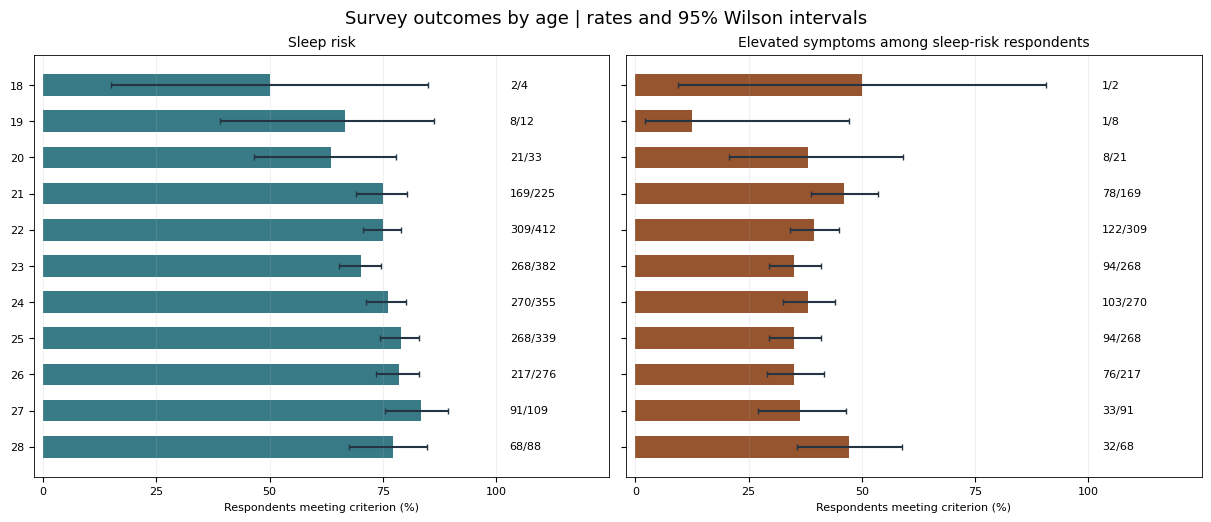

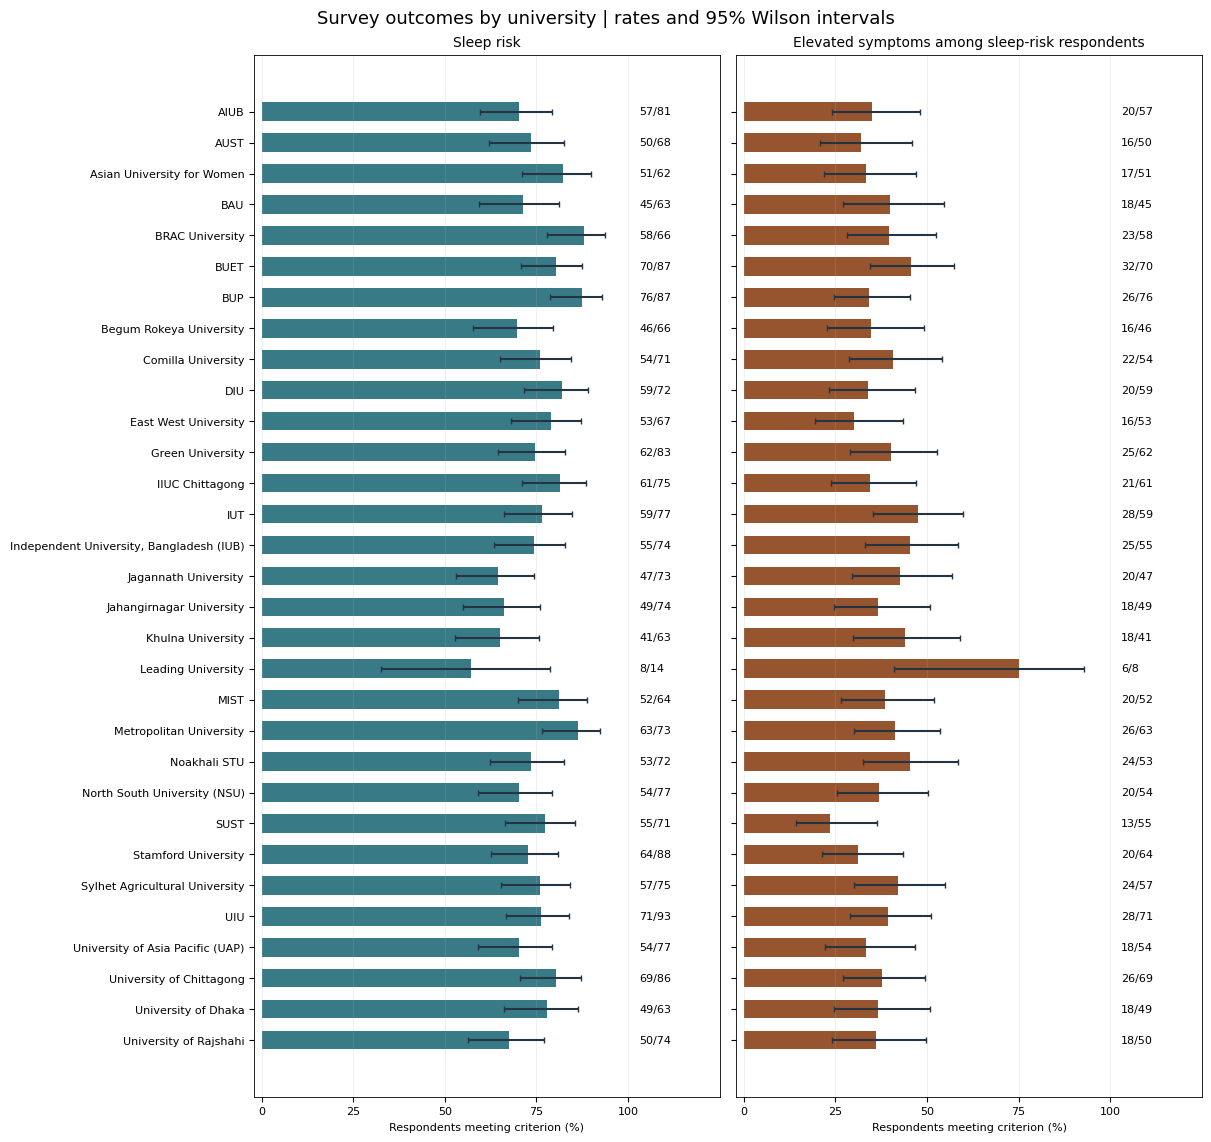

In [40]:
# One descriptive threshold permits comparisons across groups. Training folds still set their own cutoffs.
descriptive_cutoff = score[sleep.eq(1)].quantile(.72)
survey = pd.DataFrame({"Age": X[age], "University": X["What is your University name?"],
                       "Sleep": sleep, "Score": score, "Elevated": score.ge(descriptive_cutoff)})
print(f"Descriptive cognitive cutoff: {descriptive_cutoff:g}/17. Missing or invalid ages: {survey.Age.isna().sum()}.")
def group_plot(field):
    results = []
    for group, rows in survey.dropna(subset=[field]).groupby(field):
        at_risk = rows.loc[rows.Sleep.eq(1)]
        for outcome, positive, n in [("Sleep risk", int(rows.Sleep.sum()), len(rows)),
                                     ("Elevated symptoms among sleep-risk respondents", int(at_risk.Elevated.sum()), len(at_risk))]:
            rate = positive/n if n else np.nan
            ci = binomtest(positive,n).proportion_ci(method="wilson") if n else (np.nan,np.nan)
            results.append((group,outcome,positive,n,rate,*ci))
    table = pd.DataFrame(results,columns=[field,"outcome","positive","n","rate","low","high"])
    table.to_csv(chart_dir / f"{field}_rates.csv",index=False)
    fig, axes = plt.subplots(1,2,figsize=(12, max(5, .31*table[field].nunique()+1.7)),sharey=True,layout="constrained")
    for ax,(outcome,g),color in zip(axes,table.groupby("outcome",sort=False),["#387b87","#96552f"]):
        y=np.arange(len(g))
        ax.barh(y,100*g.rate,color=color,height=.60)
        ax.errorbar(100*g.rate,y,xerr=np.maximum(0,100*np.array([g.rate-g.low,g.high-g.rate])),fmt="none",ecolor="#253442",capsize=2)
        for pos,row in enumerate(g.itertuples()):
            ax.text(103,pos,f"{row.positive}/{row.n}",va="center",fontsize=8)
        ax.set(xlim=(-2,125),xticks=[0,25,50,75,100],xlabel="Respondents meeting criterion (%)")
        ax.set_title(outcome,fontsize=10); ax.grid(axis="x",alpha=.18)
        labels=[str(int(i)) if field=="Age" else str(i) for i in g[field]]
        ax.set_yticks(y,labels,fontsize=8)
    axes[0].invert_yaxis()
    fig.suptitle(f"Survey outcomes by {field.lower()} | rates and 95% Wilson intervals",fontsize=13)
    save_chart(fig,field.lower()+"_rates")
    return table
age_rates = group_plot("Age")
university_rates = group_plot("University")


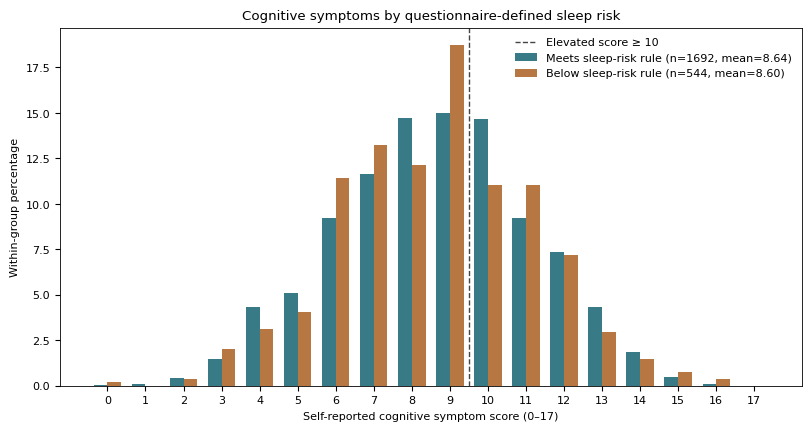

In [41]:
fig,ax=plt.subplots(figsize=(8,4.2),layout="constrained")
for label,rows,color,offset in [("Meets sleep-risk rule",survey[survey.Sleep.eq(1)],"#387b87",-.18),
                                ("Below sleep-risk rule",survey[survey.Sleep.eq(0)],"#b67743",.18)]:
    dist=rows.Score.value_counts(normalize=True).reindex(range(18),fill_value=0)
    ax.bar(dist.index+offset,100*dist,.36,color=color,label=f"{label} (n={len(rows)}, mean={rows.Score.mean():.2f})")
ax.axvline(descriptive_cutoff-.5,color="#444444",ls="--",lw=1,label=f"Elevated score ≥ {descriptive_cutoff:g}")
ax.set(xticks=range(18),xlabel="Self-reported cognitive symptom score (0–17)",ylabel="Within-group percentage",title="Cognitive symptoms by questionnaire-defined sleep risk")
ax.legend(frameon=False,fontsize=8);save_chart(fig,"sleep_cognition")


## 4. Define the four component models and their training pipelines

In [42]:
class SymptomANN(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.layers = nn.Sequential(nn.Linear(width,128), nn.ReLU(), nn.Dropout(.6),
                                    nn.Linear(128,64), nn.ReLU(), nn.Dropout(.4),
                                    nn.Linear(64,1), nn.Sigmoid())
    def forward(self,x):
        return self.layers(x).flatten()

def make_preprocessor(raw):
    categorical = [c for c in raw if c != age]
    return ColumnTransformer([
        ('age',make_pipeline(SimpleImputer(strategy='median'),StandardScaler()),[age] if age in raw else []),
        ('categories',OneHotEncoder(handle_unknown='ignore',sparse_output=False),categorical)])

def fit_models(raw, y, seed):
    categorical = [c for c in raw if c != age]
    cat_params = dict(iterations=800,depth=5,learning_rate=.002,eval_metric='AUC',
                      verbose=False,thread_count=2,allow_writing_files=False,random_seed=seed)
    cat = CatBoostClassifier(**cat_params).fit(raw,y,cat_features=categorical)
    prep = make_preprocessor(raw)
    a = prep.fit_transform(raw).astype('float32')
    xgb = XGBClassifier(n_estimators=180,max_depth=3,learning_rate=.045,
                        eval_metric='logloss',n_jobs=2,random_state=seed).fit(a,y)
    lgb = LGBMClassifier(n_estimators=180,num_leaves=15,learning_rate=.045,
                         n_jobs=2,random_state=seed,verbosity=-1).fit(pd.DataFrame(a),y)
    torch.manual_seed(seed)
    net = SymptomANN(a.shape[1])
    loader = DataLoader(TensorDataset(torch.from_numpy(a),torch.tensor(y,dtype=torch.float32)),
                        batch_size=16,shuffle=True,generator=torch.Generator().manual_seed(seed))
    opt = torch.optim.Adam(net.parameters(),lr=.008)
    loss_fn = nn.BCELoss()
    net.train()
    for epoch in range(40):
        for batch,target in loader:
            opt.zero_grad()
            loss = loss_fn(net(batch),target)
            loss.backward()
            opt.step()
    net.eval()
    return prep,cat,xgb,lgb,net,float(y.mean())

def component_scores(models,raw):
    prep,cat,xgb,lgb,net,prior = models
    a = prep.transform(raw).astype('float32')
    with torch.no_grad():
        ann = net(torch.from_numpy(a)).numpy()
    p = pd.DataFrame({'Majority':prior,'CatBoost':cat.predict_proba(raw)[:,1],
                      'XGBoost':xgb.predict_proba(a)[:,1],
                      'LightGBM':lgb.predict_proba(pd.DataFrame(a))[:,1],'ANN':ann})
    return p

## 5. Define the target, inner validation and learned stacking
Each base-model fit uses labels from its own training partition. A regularized logistic regression learns from scores for inner validation respondents. The base models are refitted on the entire outer training fold before testing.

For the cognitive task, each inner validation row also receives a probability from an entire stack trained without that row. Three subfolds within the inner training set provide inputs for its logistic meta-model. The operating threshold maximizes inner balanced accuracy, with ties resolved toward 0.50. Fixed and tuned thresholds are tested on identical outer probabilities.

In [43]:
def get_labels(task, train):
    if task == 'Sleep risk':
        return sleep.to_numpy(),np.nan
    cutoff = score.iloc[train].quantile(.72)
    return (score >= cutoff).astype(int).to_numpy(),cutoff

BASE = ['CatBoost', 'XGBoost', 'LightGBM', 'ANN']
PAIR = ['CatBoost', 'ANN']

def fit_branches(raw, y, seed):
    full = fit_models(raw, y, seed)
    ranking = pd.Series(full[1].get_feature_importance(), index=raw.columns).sort_values(
        ascending=False, kind='stable')
    chosen = ranking.index[:6].tolist()
    reduced = fit_models(raw[chosen], y, seed)
    return full, reduced, ranking

def inner_stack_head(train_ids, seed):
    # This complete stack is trained without the inner validation respondents.
    values = pd.DataFrame(index=range(len(train_ids)), columns=BASE, dtype=float)
    for fold, (i, j) in enumerate(KFold(3, shuffle=True, random_state=seed).split(train_ids)):
        subtrain = train_ids[i]
        labels, _ = get_labels('Cognitive symptoms', subtrain)
        models = fit_models(X.iloc[subtrain], labels[subtrain], seed + fold + 1)
        values.iloc[j] = component_scores(models, X.iloc[train_ids[j]])[BASE].to_numpy()
    labels, _ = get_labels('Cognitive symptoms', train_ids)
    return LogisticRegression().fit(values, labels[train_ids])

def choose_threshold(y, scores):
    fpr, tpr, thresholds = roc_curve(y, scores, drop_intermediate=False)
    # Include 0.50 explicitly so equal utility does not force a change.
    finite = np.isfinite(thresholds)
    objective = np.r_[.5 * (1 + tpr[finite] - fpr[finite]),
                      balanced_accuracy_score(y, scores >= .5), .5]
    thresholds = np.r_[thresholds[finite], .5, np.nextafter(scores.max(), np.inf)]
    candidates = thresholds[np.isclose(objective, objective.max(), rtol=0, atol=1e-12)]
    return float(candidates[np.argmin(abs(candidates - .5))])

def fit_stack(task, train, labels, seed):
    oof = pd.DataFrame(np.nan, index=range(len(train)), columns=BASE)
    reduced_oof = oof.copy()
    splits = (StratifiedKFold(3, shuffle=True, random_state=seed).split(train, labels[train])
              if task == 'Sleep risk' else KFold(3, shuffle=True, random_state=seed).split(train))
    threshold_scores = np.full(len(train), np.nan)
    coverage = np.zeros(len(train), dtype=int)
    for fold, (i, j) in enumerate(splits, 1):
        assert np.intersect1d(i, j).size == 0
        coverage[j] += 1
        fit_ids, held_ids = train[i], train[j]
        inner_labels, _ = get_labels(task, fit_ids)
        full, reduced, ranking = fit_branches(X.iloc[fit_ids], inner_labels[fit_ids], seed + fold)
        raw = X.iloc[held_ids]
        oof.iloc[j] = component_scores(full, raw)[BASE].to_numpy()
        if task == 'Cognitive symptoms':
            calibration_head = inner_stack_head(fit_ids, seed + 100 * fold)
            threshold_scores[j] = calibration_head.predict_proba(oof.iloc[j])[:, 1]
        reduced_oof.iloc[j] = component_scores(reduced, raw[ranking.index[:6]])[BASE].to_numpy()
    assert (coverage == 1).all() and not oof.isna().any().any()
    pair_head = LogisticRegression().fit(oof[PAIR], labels[train])
    full_head = LogisticRegression().fit(oof, labels[train])
    reduced_head = LogisticRegression().fit(reduced_oof, labels[train])
    full, reduced, ranking = fit_branches(X.iloc[train], labels[train], seed)
    threshold = .5
    if task == 'Cognitive symptoms':
        assert np.isfinite(threshold_scores).all()
        threshold = choose_threshold(labels[train], threshold_scores)
    return full, reduced, ranking, pair_head, full_head, reduced_head, threshold

## 6. Test on each outer fold and reconcile every reported count
Confusion matrix rows are observed classes and columns are predicted classes, ordered 0 then 1. The 95% Wilson intervals quantify fold-specific uncertainty for accuracy. Cross-fold dispersion is reported as sample SD.

Ordinary and balanced logistic regression use a fixed 0.50 threshold. Ridge regression predicts the 0–17 symptom score directly, measured by MAE against a training-median comparator. Both score models use the outer training symptom cutoff for their binary decisions. McNemar tests retain the original fixed-threshold stack versus four standalone components.

In [44]:
records, comparisons, regression = [], [], []
fitted = {}
selection = []
def evaluate_fold(task, stage, scores, truth):
    stack_correct = (scores['Four-model stack'].to_numpy() >= 0.5) == truth
    for model in BASE:
        model_correct = (scores[model].to_numpy() >= 0.5) == truth
        wins = int((stack_correct & ~model_correct).sum())
        losses = int((model_correct & ~stack_correct).sum())
        discordant = wins + losses
        p_exact = binomtest(wins, discordant, 0.5).pvalue if discordant else 1.0
        comparisons.append(dict(task=task, partition=stage, comparator=model,
                                stack_only_correct=wins, comparator_only_correct=losses,
                                accuracy_difference_pp=100*(wins-losses)/len(truth), p_exact=p_exact))

def run_partition(task,stage,train,val,seed):
    assert np.intersect1d(train, val).size == 0
    labels,cutoff = get_labels(task,train)
    full, reduced, ranking, pair_head, full_head, reduced_head, tuned_threshold = fit_stack(task, train, labels, seed)
    truth = labels[val]
    raw = X.iloc[val]
    p = component_scores(full, raw)
    p['CatBoost–ANN stack'] = pair_head.predict_proba(p[PAIR])[:, 1]
    p['Four-model stack'] = full_head.predict_proba(p[BASE])[:, 1]
    reduced_scores = component_scores(reduced, raw[ranking.index[:6]])
    p['Top-6 stack'] = reduced_head.predict_proba(reduced_scores[BASE])[:, 1]
    thresholds = {name: .5 for name in p}
    if task == 'Cognitive symptoms':
        p['Tuned stack'] = p['Four-model stack']
        thresholds['Tuned stack'] = tuned_threshold
        x_train = X.iloc[train]
        for name, weight in [('Logistic', None), ('Balanced logistic', 'balanced')]:
            model = make_pipeline(make_preprocessor(x_train),
                                  LogisticRegression(max_iter=2000, class_weight=weight))
            model.fit(x_train, labels[train])
            p[name] = model.predict_proba(raw)[:, 1]
            thresholds[name] = .5

        model = make_pipeline(make_preprocessor(x_train), Ridge(alpha=1.0))
        model.fit(x_train, score.iloc[train])
        predicted_score = np.clip(model.predict(raw), 0, 17)
        median_score = np.full(len(val), score.iloc[train].median())
        for name, estimate in [('Ridge score', predicted_score), ('Median score', median_score)]:
            p[name] = estimate
            thresholds[name] = cutoff
            regression.append(dict(partition=stage, model=name, n_test=len(val),
                                   mae=mean_absolute_error(score.iloc[val], estimate)))
    for rank,(feature,value) in enumerate(ranking.items(),1):
        selection.append(dict(task=task,partition=stage,feature=feature,rank=rank,
                              catboost_importance=value,selected=rank<=6))
    evaluate_fold(task, stage, p, truth)
    for name in p:
        hard = p[name].to_numpy() >= thresholds[name]
        tn,fp,fn,tp = confusion_matrix(truth,hard,labels=[0,1]).ravel()
        n_test = len(truth)
        n_positive = int(hard.sum())
        assert tn+fp+fn+tp == n_test
        assert tp+fp == n_positive and tp+fn == truth.sum()
        assert np.isclose((tn+tp)/n_test, accuracy_score(truth,hard))
        ci = binomtest(int((hard==truth).sum()),len(truth)).proportion_ci(method='wilson')
        records.append(dict(task=task, partition=stage, model=name, n_train=len(train), n_test=n_test,
                            decision_threshold=thresholds[name], specificity=tn/(tn+fp), score_cutoff=cutoff, predicted_positive=n_positive,
                            observed_positive=int(truth.sum()), accuracy=accuracy_score(truth,hard),
                            balanced_accuracy=balanced_accuracy_score(truth,hard),
                            precision=precision_score(truth,hard,zero_division=0),
                            recall=recall_score(truth,hard), f1=f1_score(truth,hard),
                            auc=roc_auc_score(truth,p[name]),tn=tn,fp=fp,fn=fn,tp=tp,
                            accuracy_low=ci.low,accuracy_high=ci.high))
    fitted[task,stage] = (full,full_head,val,truth)

## 7. Run five-fold cross-validation and report mean ± sample SD

In [45]:
for task,train in groups.items():
    if task == 'Sleep risk':
        splits = StratifiedKFold(5,shuffle=True,random_state=SEED).split(train,sleep.iloc[train])
    else:
        splits = KFold(5,shuffle=True,random_state=SEED).split(train)
    tested = []
    for fold,(i,j) in enumerate(splits,1):
        print(f'{task}: training fold {fold}/5', flush=True)
        tested.extend(train[j])
        run_partition(task,f'fold_{fold}',train[i],train[j],SEED+fold)
    np.testing.assert_array_equal(np.sort(tested), np.sort(train))
    print(f'Completed {task}',flush=True)
metrics = pd.DataFrame(records)
pd.DataFrame(selection).to_csv(out/'training_feature_ranks.csv',index=False)
metrics.to_csv(out/'metrics.csv',index=False)
display(metrics[['task','partition','model','accuracy','balanced_accuracy','precision','recall','specificity','f1','auc']].round(3))
columns = ['accuracy','balanced_accuracy','precision','recall','specificity','f1','auc']
cv = metrics.groupby(['task','model'])[columns].agg(['mean','std'])
cv.to_csv(out/'cross_validation_summary.csv')
display(cv.round(3))

# Adjust the exploratory fold-specific tests across all task, fold and model comparisons.
paired = pd.DataFrame(comparisons)
ordered = paired.p_exact.sort_values()
paired['p_holm'] = (ordered * np.arange(len(ordered), 0, -1)).cummax().clip(upper=1)
paired.to_csv(out/'fold_mcnemar.csv', index=False)
display(paired)
display(metrics.loc[metrics.model.eq('Four-model stack'),
        ['task','partition','n_train','n_test','score_cutoff','tn','fp','fn','tp',
         'predicted_positive','accuracy','accuracy_low','accuracy_high']].round(4))
reg = pd.DataFrame(regression)
reg.to_csv(out/'cognitive_score_regression_by_fold.csv', index=False)
reg_summary = reg.groupby('model').mae.agg(['mean', 'std'])
reg_summary.to_csv(out/'cognitive_score_regression_summary.csv')
display(reg_summary)
display(metrics.loc[metrics.task.eq('Cognitive symptoms') & metrics.model.isin(
    ['Four-model stack','Tuned stack','Balanced logistic','Logistic','Ridge score','Median score']),
    ['partition','model','decision_threshold','accuracy','balanced_accuracy','recall','specificity','auc']])


Sleep risk: training fold 1/5
Sleep risk: training fold 2/5
Sleep risk: training fold 3/5
Sleep risk: training fold 4/5
Sleep risk: training fold 5/5
Completed Sleep risk
Cognitive symptoms: training fold 1/5
Cognitive symptoms: training fold 2/5
Cognitive symptoms: training fold 3/5
Cognitive symptoms: training fold 4/5
Cognitive symptoms: training fold 5/5
Completed Cognitive symptoms


,task,partition,model,accuracy,balanced_accuracy,precision,recall,specificity,f1,auc
0,Sleep risk,fold_1,Majority,0.757,0.500,0.757,1.000,0.000,0.861,0.500
1,Sleep risk,fold_1,CatBoost,0.757,0.500,0.757,1.000,0.000,0.861,0.548
2,Sleep risk,fold_1,XGBoost,0.754,0.502,0.757,0.994,0.009,0.860,0.507
3,Sleep risk,fold_1,LightGBM,0.748,0.507,0.759,0.976,0.037,0.854,0.468
4,Sleep risk,fold_1,ANN,0.692,0.479,0.748,0.894,0.064,0.815,0.470
...,...,...,...,...,...,...,...,...,...,...
100,Cognitive symptoms,fold_5,Tuned stack,0.527,0.480,0.339,0.306,0.654,0.322,0.445
101,Cognitive symptoms,fold_5,Logistic,0.571,0.470,0.256,0.089,0.850,0.132,0.486
102,Cognitive symptoms,fold_5,Balanced logistic,0.518,0.514,0.380,0.500,0.528,0.432,0.487
103,Cognitive symptoms,fold_5,Ridge score,0.639,0.508,1.000,0.016,1.000,0.032,0.487


accuracy        balanced_accuracy  \
                                          mean    std              mean   
task               model                                                  
Cognitive symptoms ANN                   0.547  0.024             0.502   
                   Balanced logistic     0.494  0.032             0.492   
                   CatBoost              0.621  0.030             0.500   
                   CatBoost–ANN stack    0.621  0.030             0.500   
                   Four-model stack      0.621  0.030             0.500   
                   LightGBM              0.571  0.021             0.493   
                   Logistic              0.589  0.030             0.494   
                   Majority              0.621  0.030             0.500   
                   Median score          0.621  0.030             0.500   
                   Ridge score           0.622  0.034             0.503   
                   Top-6 stack           0.621  0.030             0.500   
                   Tuned stack           0.515  0.106             0.490   
                   XGBoost               0.593  0.031             0.491   
Sleep risk         ANN                   0.713  0.022             0.496   
                   CatBoost              0.757  0.001             0.500   
                   CatBoost–ANN stack    0.757  0.001             0.500   
                   Four-model stack      0.757  0.001             0.500   
                   LightGBM              0.753  0.003             0.509   
                   Majority              0.757  0.001             0.500   
                   Top-6 stack           0.757  0.001             0.500   
                   XGBoost               0.752  0.006             0.500   

                                             precision        recall         \
                                         std      mean    std   mean    std   
task               model                                                      
Cognitive symptoms ANN                 0.030     0.381  0.059  0.315  0.084   
                   Balanced logistic   0.033     0.372  0.040  0.484  0.048   
                   CatBoost            0.000     0.000  0.000  0.000  0.000   
                   CatBoost–ANN stack  0.000     0.000  0.000  0.000  0.000   
                   Four-model stack    0.000     0.000  0.000  0.000  0.000   
                   LightGBM            0.024     0.364  0.082  0.173  0.028   
                   Logistic            0.021     0.362  0.099  0.102  0.027   
                   Majority            0.000     0.000  0.000  0.000  0.000   
                   Median score        0.000     0.000  0.000  0.000  0.000   
                   Ridge score         0.005     0.650  0.487  0.010  0.007   
                   Top-6 stack         0.000     0.000  0.000  0.000  0.000   
                   Tuned stack         0.016     0.305  0.173  0.471  0.422   
                   XGBoost             0.012     0.330  0.105  0.068  0.030   
Sleep risk         ANN                 0.024     0.755  0.010  0.918  0.022   
                   CatBoost            0.000     0.757  0.001  1.000  0.000   
                   CatBoost–ANN stack  0.000     0.757  0.001  1.000  0.000   
                   Four-model stack    0.000     0.757  0.001  1.000  0.000   
                   LightGBM            0.007     0.760  0.003  0.985  0.010   
                   Majority            0.000     0.757  0.001  1.000  0.000   
                   Top-6 stack         0.000     0.757  0.001  1.000  0.000   
                   XGBoost             0.006     0.757  0.001  0.992  0.009   

                                      specificity            f1           auc  \
                                             mean    std   mean    std   mean   
task               model                                                        
Cognitive symptoms ANN                      0.689  0.061  0.341  0.066  0.511   
                

,task,partition,comparator,stack_only_correct,comparator_only_correct,accuracy_difference_pp,p_exact,p_holm
0,Sleep risk,fold_1,CatBoost,0,0,0.000000,1.000000,1.000000
1,Sleep risk,fold_1,XGBoost,2,1,0.223214,1.000000,1.000000
2,Sleep risk,fold_1,LightGBM,8,4,0.892857,0.387695,1.000000
3,Sleep risk,fold_1,ANN,36,7,6.473214,0.000009,0.000359
4,Sleep risk,fold_2,CatBoost,0,0,0.000000,1.000000,1.000000
5,Sleep risk,fold_2,XGBoost,5,2,0.671141,0.453125,1.000000
6,Sleep risk,fold_2,LightGBM,4,3,0.223714,1.000000,1.000000
7,Sleep risk,fold_2,ANN,27,4,5.145414,0.000034,0.001290
8,Sleep risk,fold_3,CatBoost,0,0,0.000000,1.000000,1.000000
9,Sleep risk,fold_3,XGBoost,0,0,0.000000,1.000000,1.000000


,task,partition,n_train,n_test,score_cutoff,tn,fp,fn,tp,predicted_positive,accuracy,accuracy_low,accuracy_high
6,Sleep risk,fold_1,1788,448,NaN,0,109,0,339,448,0.7567,0.7149,0.7941
14,Sleep risk,fold_2,1789,447,NaN,0,109,0,338,447,0.7562,0.7143,0.7937
22,Sleep risk,fold_3,1789,447,NaN,0,109,0,338,447,0.7562,0.7143,0.7937
30,Sleep risk,fold_4,1789,447,NaN,0,109,0,338,447,0.7562,0.7143,0.7937
38,Sleep risk,fold_5,1789,447,NaN,0,108,0,339,447,0.7584,0.7166,0.7958
46,Cognitive symptoms,fold_1,1353,339,10.0,197,0,142,0,0,0.5811,0.5280,0.6324
59,Cognitive symptoms,fold_2,1353,339,10.0,203,0,136,0,0,0.5988,0.5458,0.6496
72,Cognitive symptoms,fold_3,1354,338,10.0,214,0,124,0,0,0.6331,0.5805,0.6828
85,Cognitive symptoms,fold_4,1354,338,10.0,222,0,116,0,0,0.6568,0.6047,0.7054
98,Cognitive symptoms,fold_5,1354,338,10.0,214,0,124,0,0,0.6331,0.5805,0.6828


,mean,std
model,,
Median score,2.059756,0.082133
Ridge score,2.131134,0.048658


,partition,model,decision_threshold,accuracy,balanced_accuracy,recall,specificity,auc
46,fold_1,Four-model stack,0.500000,0.581121,0.500000,0.000000,1.000000,0.544041
48,fold_1,Tuned stack,0.350444,0.418879,0.500000,1.000000,0.000000,0.544041
49,fold_1,Logistic,0.500000,0.545723,0.485272,0.112676,0.857868,0.442482
50,fold_1,Balanced logistic,0.500000,0.448378,0.446736,0.436620,0.456853,0.444591
51,fold_1,Ridge score,10.000000,0.575221,0.495907,0.007042,0.984772,0.459784
52,fold_1,Median score,10.000000,0.581121,0.500000,0.000000,1.000000,0.500000
59,fold_2,Four-model stack,0.500000,0.598820,0.500000,0.000000,1.000000,0.472254
61,fold_2,Tuned stack,0.347822,0.398230,0.468415,0.823529,0.113300,0.472254
62,fold_2,Logistic,0.500000,0.595870,0.512098,0.088235,0.935961,0.532309
63,fold_2,Balanced logistic,0.500000,0.530973,0.529502,0.522059,0.536946,0.532744


## 8. Audit the preliminary manuscript numbers
The following historical counts are transcribed from the draft. They are kept separate from the corrected performance estimates.

In [46]:
old_tn, old_tp, old_fn, old_fp = 212, 192, 43, 63
old_n = old_tn + old_tp + old_fn + old_fp
legacy = pd.DataFrame([
    ('Test respondents', old_n, 447),
    ('Predicted positive respondents', old_tp + old_fp, 367),
    ('Accuracy (%)', 100*(old_tp + old_tn)/old_n, 95.20),
], columns=['quantity', 'implied_by_draft_matrix', 'separately_reported'])
legacy.to_csv(out/'historical_count_check.csv', index=False)
display(legacy.round(2))

,quantity,implied_by_draft_matrix,separately_reported
0,Test respondents,510.00,447.0
1,Predicted positive respondents,255.00,367.0
2,Accuracy (%),79.22,95.2


## 9. Measure permutation importance
Within each validation fold, shuffle each feature five times. Report the mean ROC-AUC decrease across folds and the standard deviation of the five fold means.

In [47]:
importance = []
for (task,fold),(models,head,ids,truth) in fitted.items():
    raw = X.iloc[ids].copy()
    base = roc_auc_score(truth,head.predict_proba(component_scores(models,raw)[BASE])[:, 1])
    rng = np.random.default_rng(SEED)
    for feature in features:
        drops = []
        for repeat in range(5):
            shuffled = raw.copy()
            shuffled[feature] = rng.permutation(raw[feature].to_numpy())
            shuffled_p = head.predict_proba(component_scores(models,shuffled)[BASE])[:, 1]
            drops.append(base-roc_auc_score(truth,shuffled_p))
        importance.append(dict(task=task,fold=fold,feature=feature,baseline_auc=base,
                               mean_auc_drop=np.mean(drops),sd_auc_drop=np.std(drops,ddof=1)))
fold_importance = pd.DataFrame(importance)
fold_importance.to_csv(out/'permutation_importance_by_fold.csv',index=False)
imp = (fold_importance.groupby(['task','feature'],as_index=False)
       .agg(baseline_auc=('baseline_auc','mean'), mean_auc_drop=('mean_auc_drop','mean'),
            sd_auc_drop=('mean_auc_drop','std')).sort_values(['task','mean_auc_drop'],ascending=[True,False]))
imp.to_csv(out/'ensemble_feature_importance.csv',index=False)
display(imp.round(4))
versions = {}
for package in ['torch','catboost','xgboost','lightgbm','scikit-learn','numpy','pandas','scipy']:
    try:
        versions[package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        versions[package] = __import__(package).__version__
pd.Series(versions,name='version').to_csv(out/'package_versions.csv')
print('Output folder:',out)

,task,feature,baseline_auc,mean_auc_drop,sd_auc_drop
6,Cognitive symptoms,How often does physical or mental fatigue prev...,0.4809,0.0105,0.0203
0,Cognitive symptoms,How many academic deadlines have you missed or...,0.4809,0.0081,0.0065
11,Cognitive symptoms,Your current year of study?,0.4809,0.0064,0.0169
5,Cognitive symptoms,How often do you wake up in the middle of the ...,0.4809,0.0020,0.0088
3,Cognitive symptoms,How often do you feel stressed?,0.4809,0.0018,0.0117
9,Cognitive symptoms,What is your age?,0.4809,0.0011,0.0122
2,Cognitive symptoms,How often do you feel cognitive load?,0.4809,-0.0019,0.0273
7,Cognitive symptoms,To what extent do you feel sleep deprivation i...,0.4809,-0.0027,0.0172
4,Cognitive symptoms,How often do you use electronic devices (phone...,0.4809,-0.0038,0.0163
8,Cognitive symptoms,What is your University name?,0.4809,-0.0053,0.0257


Output folder: /kaggle/working/neuro_screen_experiment_results


## 10. Generate publication figures
The comparison plots use the model scores calculated in this run. Each bar is the mean across five validation folds. Error bars span one sample standard deviation.

In [48]:
from zipfile import ZipFile, ZIP_DEFLATED
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import numpy as np
import pandas as pd

figure_dir = out / "figures"
figure_dir.mkdir(exist_ok=True)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 8,
                     "pdf.fonttype": 42, "axes.linewidth": 0.6})

def export(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(figure_dir / f"{name}.{ext}", dpi=600, facecolor="white")
    plt.show()

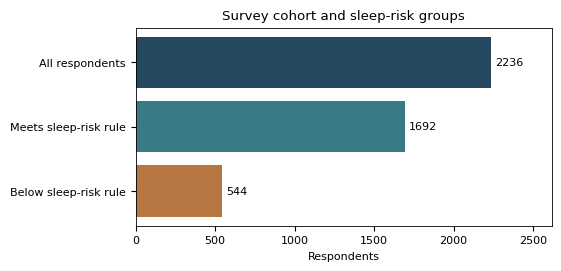

In [49]:
# Figure 1: cohort size and sleep-risk eligibility.
sizes = [len(sleep), int(sleep.sum()), int((sleep==0).sum())]
fig, ax = plt.subplots(figsize=(5.5,2.6),layout="constrained")
bars=ax.barh(["All respondents","Meets sleep-risk rule","Below sleep-risk rule"],sizes,color=["#254760","#387b87","#b67743"])
ax.bar_label(bars,padding=3)
ax.invert_yaxis()
ax.set(xlim=(0,max(sizes)*1.17),xlabel="Respondents",title="Survey cohort and sleep-risk groups")
export(fig,"Fig1_cohort_sizes")


In [50]:
folds = metrics.copy()
model_order = ["Majority", "CatBoost", "XGBoost", "LightGBM", "ANN",
               "CatBoost–ANN stack", "Four-model stack", "Top-6 stack"]
assert not folds.duplicated(["task", "partition", "model"]).any()
assert folds.groupby(["task", "model"]).size().eq(5).all()

bounds = folds.groupby(["task", "model"])[["auc", "balanced_accuracy"]].agg(["mean", "std"])
lower = min(.38, *(float((bounds[k]["mean"] - bounds[k]["std"]).min()) - .01 for k in ["auc", "balanced_accuracy"]))
upper = max(.62, *(float((bounds[k]["mean"] + bounds[k]["std"]).max()) + .01 for k in ["auc", "balanced_accuracy"]))

def performance(task, filename):
    rows = folds.loc[folds.task.eq(task)]
    order = rows.model.drop_duplicates().tolist()
    fig, axes = plt.subplots(1, 2, figsize=(4.4, .25*len(order)+.65), sharey=True)
    fig.subplots_adjust(left=.335, right=.973, top=.84, bottom=.19, wspace=.20)
    y = np.arange(len(order))
    for ax, key, title in zip(axes, ["auc", "balanced_accuracy"],
                             ["ROC-AUC", "Balanced accuracy"]):
        agg = rows.groupby("model")[key].agg(["mean","std"]).loc[order]
        ax.axvline(.5, color=".58", linestyle="--", lw=.7)
        ax.barh(y,agg["mean"],xerr=agg["std"],height=.6,color="#39727c",capsize=2)
        ax.set(xlim=(0, max(1,upper)), ylim=(len(order)-.5,-.5))
        ax.set_title(title, fontsize=8)
        ax.tick_params(labelsize=7, length=2)
        ax.spines[["top","right"]].set_visible(False)
    axes[0].set_yticks(y, order, fontsize=7)
    export(fig, filename)
    return fig

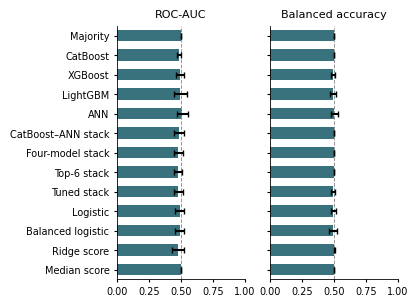

In [51]:
fig = performance("Cognitive symptoms", "Fig2_cognitive_symptoms")

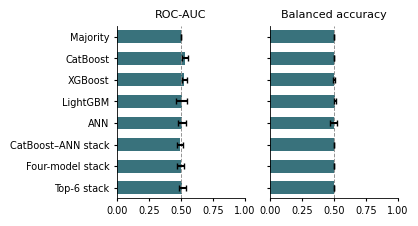

In [52]:
fig = performance("Sleep risk", "Fig3_sleep_risk")

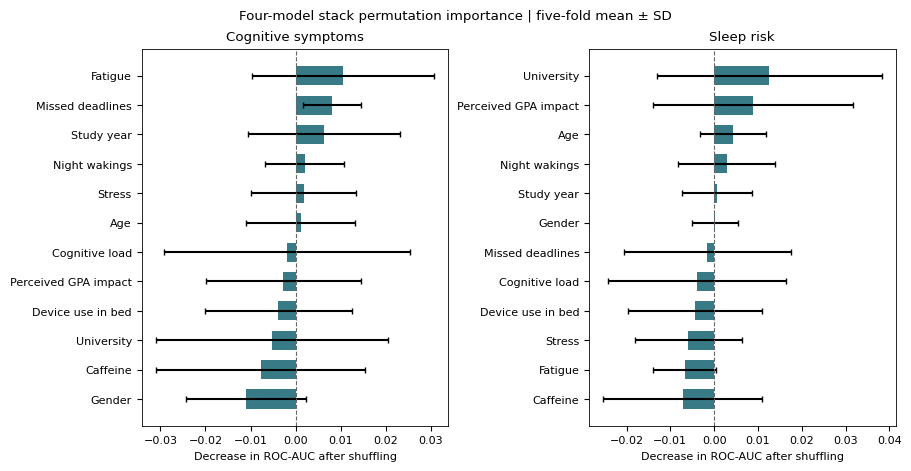

In [53]:
short_features = ["Age","Gender","University","Study year","Caffeine","Device use in bed","Cognitive load","Stress","Night wakings","Missed deadlines","Perceived GPA impact","Fatigue"]
labels = dict(zip(features,short_features))
fig,axes = plt.subplots(1,2,figsize=(9,4.6),layout="constrained")
for ax,(task,g) in zip(axes,imp.groupby("task",sort=True)):
    g=g.sort_values("mean_auc_drop")
    ax.barh(g.feature.map(labels),g.mean_auc_drop,xerr=g.sd_auc_drop,color="#387b87",height=.65,capsize=2)
    ax.axvline(0,color="#666666",ls="--",lw=.8)
    ax.set(title=task,xlabel="Decrease in ROC-AUC after shuffling")
    ax.tick_params(axis="y",labelsize=8)
fig.suptitle("Four-model stack permutation importance | five-fold mean ± SD")
save_chart(fig,"feature_importance")


In [55]:
archive_path = out.parent / "Neuro-Screen_Experiment_Results.zip"
with ZipFile(archive_path, "w", ZIP_DEFLATED) as archive:
    for filename in ["cognitive_score_regression_by_fold.csv", "cognitive_score_regression_summary.csv", "metrics.csv", "source_and_ethics.csv", "feature_overlap_audit.csv",
                     "cognitive_scoring_key.csv", "historical_count_check.csv", "cross_validation_summary.csv", "fold_mcnemar.csv",
                     "training_feature_ranks.csv", "permutation_importance_by_fold.csv",
                     "ensemble_feature_importance.csv", "package_versions.csv"]:
        archive.write(out / filename, filename)
    for stem in ["Fig1_cohort_sizes", "Fig2_cognitive_symptoms", "Fig3_sleep_risk"]:
        for ext in ["pdf", "png"]:
            path = figure_dir / f"{stem}.{ext}"
            archive.write(path, "figures/" + path.name)
    for path in sorted(chart_dir.iterdir()):
        if path.suffix in {".png",".pdf",".csv"}:
            archive.write(path,"survey_and_model_figures/"+path.name)
print("Download your tables and figures from:", archive_path)

Download your tables and figures from: /kaggle/working/Neuro-Screen_Experiment_Results.zip
